## 1. Find Gradient-Informed Threshold

In this section, we use the H2 gradient results to identify a gradient-informed heuristic threshold for the retrieval decision score \(d\).

First, we load the aggregated gradient results and consider only the **Total** data, which combines samples across different hop counts.

For each retrieval ratio, we identify a characteristic decision score based on the gradient curve:

- **`0:3`**: all retrieved documents are non-supporting. We take the \(d\) corresponding to the **maximum positive gradient**.
- **`1:2`**, **`2:1`**, and **`3:0`**: these conditions contain supporting documents. We take the \(d\) corresponding to the **minimum gradient** (the valley) for each condition.

This gives four characteristic decision scores:

\[
d_{0:3}^{\mathrm{peak}},
\quad
d_{1:2}^{\mathrm{valley}},
\quad
d_{2:1}^{\mathrm{valley}},
\quad
d_{3:0}^{\mathrm{valley}}.
\]

We then compute their mean and use it as the gradient-informed heuristic threshold:

\[
\tau_{\mathrm{grad}}
=
\frac{
d_{0:3}^{\mathrm{peak}}
+
d_{1:2}^{\mathrm{valley}}
+
d_{2:1}^{\mathrm{valley}}
+
d_{3:0}^{\mathrm{valley}}
}{4}.
\]

The resulting threshold is used to focus the visualization on the region

\[
d \geq \tau_{\mathrm{grad}},
\]

by removing points with decision scores below the threshold from the plotted gradient curves.

> **Note:** This threshold is a gradient-informed heuristic operating point derived from the observed H2 gradient curves. It is not a directly supervised or mathematically optimal retrieval threshold.

### 1.1 Load H2 Gradient Results

Load the aggregated H2 gradient results from `gradient_summary.csv`.

The file contains the mean gradient of the LM loss with respect to the retrieval decision score \(d\), grouped by hop count, retrieval ratio, and decision score.

In [1]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("gradient_results/plots/gradient_summary.csv")

df = pd.read_csv(DATA_PATH)

print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

df.head()

Shape: (528, 5)
Columns: ['hop', 'retrieval_ratio', 'decision_score', 'mean_gradient', 'n_samples']


,hop,retrieval_ratio,decision_score,mean_gradient,n_samples
0,2-hop,3:0,0.0000,NaN,0
1,2-hop,3:0,0.0312,NaN,0
2,2-hop,3:0,0.0625,NaN,0
3,2-hop,3:0,0.0938,NaN,0
4,2-hop,3:0,0.1250,NaN,0


### 1.2 Extract Total Data

Select only the `Total` rows from the H2 gradient results.

The `Total` data aggregates the gradient results across all hop counts and is used for determining the gradient-informed threshold.

In [2]:
total_df = df[df["hop"] == "Total"].copy()

print(f"Shape: {total_df.shape}")

total_df.head()

Shape: (132, 5)


,hop,retrieval_ratio,decision_score,mean_gradient,n_samples
396,Total,3:0,0.0000,-0.286350,494
397,Total,3:0,0.0312,-0.220648,494
398,Total,3:0,0.0625,-0.138676,494
399,Total,3:0,0.0938,-0.224021,494
400,Total,3:0,0.1250,-0.035823,494


### 1.3 Extract Characteristic Decision Scores

For each retrieval ratio, identify a characteristic decision score from the gradient curve:

- `0:3`: select the decision score with the **maximum positive gradient**.
- `1:2`, `2:1`, `3:0`: select the decision score with the **minimum gradient**.

These points represent the peak or valley of the corresponding gradient curves and will be used to estimate the threshold.

In [3]:
ratios = ["0:3", "1:2", "2:1", "3:0"]

characteristic_rows = {}

for ratio in ratios:
    ratio_df = total_df[
        (total_df["retrieval_ratio"] == ratio) &
        (total_df["n_samples"] > 0)
    ].dropna(subset=["mean_gradient"])

    if ratio == "0:3":
        row = ratio_df.loc[ratio_df["mean_gradient"].idxmax()]
    else:
        row = ratio_df.loc[ratio_df["mean_gradient"].idxmin()]

    characteristic_rows[ratio] = row

characteristic_df = pd.DataFrame(characteristic_rows).T

characteristic_df[
    ["decision_score", "mean_gradient", "n_samples"]
]

,decision_score,mean_gradient,n_samples
0:3,0.375,0.401607,1024
1:2,0.4375,-1.235579,1024
2:1,0.4375,-2.123264,1024
3:0,0.4375,-2.478448,494


### 1.4 Compute Mean Decision Score

Compute the mean of the characteristic decision scores obtained from the four retrieval ratios.

The resulting mean is used as the gradient-informed heuristic threshold:

\[
\tau_{\mathrm{grad}}
=
\mathrm{mean}
\left(
d_{0:3}^{\mathrm{peak}},
d_{1:2}^{\mathrm{valley}},
d_{2:1}^{\mathrm{valley}},
d_{3:0}^{\mathrm{valley}}
\right).
\]

In [4]:
threshold = characteristic_df["decision_score"].mean()

print(f"Mean decision score: {threshold:.4f}")

Mean decision score: 0.4219


### 1.5 Filter by Gradient-Informed Threshold

Filter the `Total` gradient results using the gradient-informed threshold obtained above.

Only data points with decision scores satisfying

\[
d \geq \tau_{\mathrm{grad}}
\]

are retained for further analysis and visualization.

In [5]:
threshold_df = total_df[
    total_df["decision_score"] >= threshold
].copy()

print(f"Threshold: {threshold:.4f}")
print(f"Shape before filtering: {total_df.shape}")
print(f"Shape after filtering: {threshold_df.shape}")

threshold_df.head()

Threshold: 0.4219
Shape before filtering: (132, 5)
Shape after filtering: (76, 5)


,hop,retrieval_ratio,decision_score,mean_gradient,n_samples
410,Total,3:0,0.4375,-2.478448,494
411,Total,3:0,0.4688,-1.874388,494
412,Total,3:0,0.5000,-1.129466,494
413,Total,3:0,0.5312,-0.726315,494
414,Total,3:0,0.5625,-0.577728,494


Saved: gradient_results\plots\gradient_vs_decision_score_total_with_threshold.png


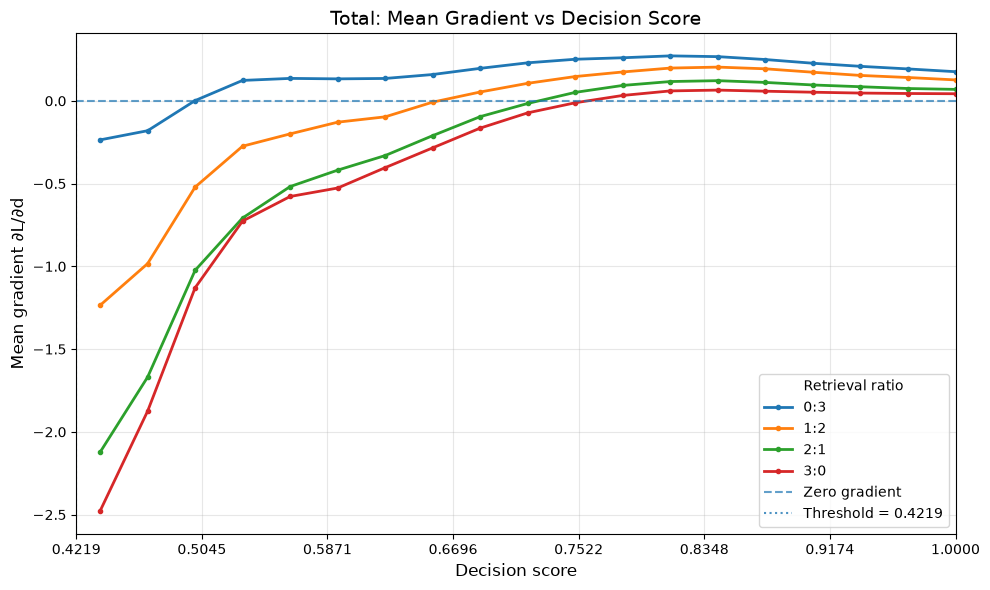

In [6]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


OUTPUT_PATH = Path(
    "gradient_results/plots/gradient_vs_decision_score_total_with_threshold.png"
)

plt.figure(figsize=(10, 6))

# Same color order as the LM-loss plot:
# 0:3 → blue
# 1:2 → orange
# 2:1 → green
# 3:0 → red
for ratio in ["0:3", "1:2", "2:1", "3:0"]:
    ratio_df = threshold_df[
        threshold_df["retrieval_ratio"] == ratio
    ].sort_values("decision_score")

    if ratio_df.empty:
        continue

    plt.plot(
        ratio_df["decision_score"],
        ratio_df["mean_gradient"],
        marker="o",
        markersize=3,
        linewidth=2,
        label=ratio,
    )

# Zero-gradient reference
plt.axhline(
    y=0.0,
    linestyle="--",
    linewidth=1.5,
    alpha=0.7,
    label="Zero gradient",
)

# Threshold reference
plt.axvline(
    x=threshold,
    linestyle=":",
    linewidth=1.5,
    alpha=0.8,
    label=f"Threshold = {threshold:.4f}",
)

plt.xlabel(
    "Decision score",
    fontsize=12,
)

plt.ylabel(
    "Mean gradient ∂L/∂d",
    fontsize=12,
)

plt.title(
    "Total: Mean Gradient vs Decision Score",
    fontsize=14,
)

plt.xlim(threshold, 1)

plt.xticks(
    np.linspace(
        threshold,
        1,
        8,
    )
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend(
    title="Retrieval ratio"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight",
)

print(f"Saved: {OUTPUT_PATH}")

plt.show()

## 2. Cost Analysis

In this section, we analyze the effect of the retrieval cost term

$$
J(d)=L_{\mathrm{LM}}(d)+\lambda d
$$

on the gradient with respect to the retrieval decision score \(d\).

The resulting gradient is

$$
\frac{\partial J}{\partial d}
=
\frac{\partial L_{\mathrm{LM}}}{\partial d}+\lambda.
$$

Equivalently, we can analyze a horizontal reference level at

$$
-\lambda.
$$

For a given \(\lambda\):

* if \(g_{\mathrm{LM}}(d)>-\lambda\), then \(g_{\mathrm{LM}}(d)+\lambda>0\), meaning that the cost term dominates the LM-loss gradient at that point;
* if \(g_{\mathrm{LM}}(d)<-\lambda\), then \(g_{\mathrm{LM}}(d)+\lambda<0\), meaning that the LM-loss gradient still dominates the retrieval cost.

The analysis is performed on `threshold_df`, i.e. the H2 gradient results restricted to the decision-score region

$$
d\geq\tau_{\mathrm{grad}}.
$$

### Analysis procedure

We proceed in four steps:

1. **Determine the sweep range for \(-\lambda\)**

   * Find the minimum gradient score in the `0:3` condition.
   * Find the minimum gradient score across all retrieval ratios.
   * Use these two values as the boundaries of the \(-\lambda\) sweep range.

2. **Sweep \(-\lambda\)**
   Generate a sequence of \(-\lambda\) values within this range using a small step size.

3. **Measure cost-dominated points**
   For each \(-\lambda\), count the number of points satisfying

   $$
   g_{\mathrm{LM}}(d)>-\lambda
   $$

   for each retrieval ratio.

   These are the points whose total gradient becomes positive after adding the retrieval cost term \(\lambda d\).

   We pay particular attention to the ratios containing supporting documents:

   * `1:2`
   * `2:1`
   * `3:0`

   because these represent cases where retrieval can provide useful evidence.

4. **Visualize and select \(\lambda\)**
   Plot the number or proportion of positive-gradient points as a function of \(\lambda\).
   The resulting curves show how increasing the retrieval cost progressively changes the balance between the LM-loss gradient and the retrieval cost.

The final \(\lambda\) is selected based on this empirical cost-dominance analysis rather than being arbitrarily specified.


In [7]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

D_MIN = 0.4219

fit_df = total_df[
    total_df["decision_score"] >= D_MIN
].copy()

ratios = ["0:3", "1:2", "2:1", "3:0"]

# Common decision-score grid
d_values = np.sort(
    fit_df["decision_score"].unique()
)

d = torch.tensor(
    d_values,
    dtype=torch.float32,
)

# Store each gradient curve
y = {}

for ratio in ratios:
    ratio_df = (
        fit_df[
            fit_df["retrieval_ratio"] == ratio
        ]
        .sort_values("decision_score")
    )

    y[ratio] = torch.tensor(
        ratio_df["mean_gradient"].values,
        dtype=torch.float32,
    )

print(f"D_MIN: {D_MIN}")
print(f"Number of decision points: {len(d_values)}")

for ratio in ratios:
    print(
        f"{ratio}: {len(y[ratio])} points"
    )

D_MIN: 0.4219
Number of decision points: 19
0:3: 19 points
1:2: 19 points
2:1: 19 points
3:0: 19 points


In [8]:
# ============================================================
# Optimize nonlinear separation boundary
# Logistic boundary
# ============================================================

MARGIN = 0.01

# ------------------------------------------------------------
# Initialize boundary parameters
# ------------------------------------------------------------

L = torch.nn.Parameter(
    torch.tensor(-1.0)
)

U_delta = torch.nn.Parameter(
    torch.tensor(1.0)
)

k_raw = torch.nn.Parameter(
    torch.tensor(1.0)
)

# Position of the logistic midpoint / inflection point
c = torch.nn.Parameter(
    torch.tensor(0.5)
)


optimizer = torch.optim.Adam(
    [L, U_delta, k_raw, c],
    lr=0.01,
)


# ============================================================
# Boundary function
# ============================================================

def boundary_function(d):

    # Enforce U > L
    U = L + F.softplus(U_delta)

    # Enforce k > 0
    k = F.softplus(k_raw)

    return (
        L
        + (U - L)
        / (
            1.0
            + torch.exp(
                -k * (d - c)
            )
        )
    )


# ============================================================
# Training
# ============================================================

NUM_STEPS = 10000

for step in range(NUM_STEPS):

    boundary = boundary_function(d)

    losses = []

    # --------------------------------------------------------
    # 0:3 should be ABOVE boundary
    #
    # y_03 >= boundary + MARGIN
    # --------------------------------------------------------

    violation_03 = (
        boundary
        + MARGIN
        - y["0:3"]
    )

    loss_03 = F.relu(
        violation_03
    ).mean()

    losses.append(loss_03)


    # --------------------------------------------------------
    # Other ratios should be BELOW boundary
    #
    # y_other <= boundary - MARGIN
    # --------------------------------------------------------

    for ratio in ["1:2", "2:1", "3:0"]:

        violation = (
            y[ratio]
            + MARGIN
            - boundary
        )

        loss_other = F.relu(
            violation
        ).mean()

        losses.append(loss_other)


    # --------------------------------------------------------
    # Equal weight for the 4 ratio groups
    # --------------------------------------------------------

    loss = torch.stack(
        losses
    ).mean()


    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


# ============================================================
# Final parameters
# ============================================================

with torch.no_grad():

    U = L + F.softplus(U_delta)
    k = F.softplus(k_raw)

print(f"L = {L.item():.6f}")
print(f"U = {U.item():.6f}")
print(f"k = {k.item():.6f}")
print(f"c = {c.item():.6f}")
print(f"Final loss = {loss.item():.6f}")

L = -1.494137
U = 0.199348
k = 17.432991
c = 0.463704
Final loss = 0.001109


In [9]:
# ============================================================
# Convert logistic boundary into final piecewise function
# ============================================================

import math


# ============================================================
# Configuration
# ============================================================

TARGET_BOUNDARY = -0.05


# ============================================================
# Retrieve learned parameters and solve f(d) = TARGET_BOUNDARY
# ============================================================

with torch.no_grad():

    # --------------------------------------------------------
    # Retrieve learned parameters
    # --------------------------------------------------------

    L_final = L.item()
    U_final = U.item()
    k_final = k.item()
    c_final = c.item()


    # --------------------------------------------------------
    # Logistic boundary:
    #
    #     f(d) = L + (U-L) / (1 + exp(-k(d-c)))
    #
    # Solve:
    #
    #     f(d0) = TARGET_BOUNDARY
    #
    # =>  exp(-k(d0-c))
    #       = (U-y) / (y-L)
    #
    # =>  d0
    #       = c + log((y-L)/(U-y)) / k
    # --------------------------------------------------------

    if not (L_final < TARGET_BOUNDARY < U_final):
        raise ValueError(
            "Cannot find a finite target crossing: "
            f"the target boundary must satisfy "
            f"L < TARGET_BOUNDARY < U, but got "
            f"L={L_final:.6f}, "
            f"TARGET_BOUNDARY={TARGET_BOUNDARY:.6f}, "
            f"U={U_final:.6f}."
        )

    if k_final == 0:
        raise ValueError(
            "Cannot find a unique crossing because k = 0."
        )

    d_zero = (
        c_final
        + math.log(
            (TARGET_BOUNDARY - L_final)
            / (U_final - TARGET_BOUNDARY)
        ) / k_final
    )


# ============================================================
# Final piecewise boundary
# ============================================================

def final_boundary(d):

    """
    Final separation function:

        d < d_zero  -> logistic boundary f(d)
        d >= d_zero -> TARGET_BOUNDARY

    where:

        f(d_zero) = TARGET_BOUNDARY
    """

    boundary = (
        L_final
        + (U_final - L_final)
        / (
            1.0
            + torch.exp(
                -k_final * (d - c_final)
            )
        )
    )

    return torch.where(
        d < d_zero,
        boundary,
        torch.full_like(d, TARGET_BOUNDARY)
    )


# ============================================================
# Compute useful coefficient
# ============================================================

AMPLITUDE = U_final - L_final


# ============================================================
# Verify the crossing
# ============================================================

boundary_at_d_zero = (
    L_final
    + AMPLITUDE
    / (
        1.0
        + math.exp(
            -k_final * (d_zero - c_final)
        )
    )
)


# ============================================================
# Print final result
# ============================================================

print("=" * 70)
print("FINAL PIECEWISE BOUNDARY")
print("=" * 70)

print()
print("Configuration:")
print(f"  Target boundary = {TARGET_BOUNDARY:.6f}")

print()
print("Learned parameters:")
print(f"  L      = {L_final:.6f}")
print(f"  U      = {U_final:.6f}")
print(f"  U - L  = {AMPLITUDE:.6f}")
print(f"  k      = {k_final:.6f}")
print(f"  c      = {c_final:.6f}")
print(f"  d_zero = {d_zero:.6f}")

print()
print("Verification:")
print(f"  f(d_zero) = {boundary_at_d_zero:.6f}")
print(f"  target    = {TARGET_BOUNDARY:.6f}")
print(f"  error     = {abs(boundary_at_d_zero - TARGET_BOUNDARY):.2e}")

print()
print("Logistic boundary:")
print(
    f"  f(d) = {L_final:.6f} "
    f"+ {AMPLITUDE:.6f} / "
    f"(1 + exp(-{k_final:.6f} * "
    f"(d - {c_final:.6f})))"
)

print()
print("Final piecewise boundary:")
print(
    f"  g(d) = {{ "
    f"{L_final:.6f} + {AMPLITUDE:.6f} / "
    f"(1 + exp(-{k_final:.6f} * "
    f"(d - {c_final:.6f}))), "
    f"if d < {d_zero:.6f}; "
    f"{TARGET_BOUNDARY:.6f}, "
    f"if d >= {d_zero:.6f} "
    f"}}"
)

print()
print("=" * 70)

FINAL PIECEWISE BOUNDARY

Configuration:
  Target boundary = -0.050000

Learned parameters:
  L      = -1.494137
  U      = 0.199348
  U - L  = 1.693485
  k      = 17.432991
  c      = 0.463704
  d_zero = 0.564456

Verification:
  f(d_zero) = -0.050000
  target    = -0.050000
  error     = 4.16e-17

Logistic boundary:
  f(d) = -1.494137 + 1.693485 / (1 + exp(-17.432991 * (d - 0.463704)))

Final piecewise boundary:
  g(d) = { -1.494137 + 1.693485 / (1 + exp(-17.432991 * (d - 0.463704))), if d < 0.564456; -0.050000, if d >= 0.564456 }



Saved: gradient_results\plots\gradient_vs_decision_score_total_nonlinear_boundary.png


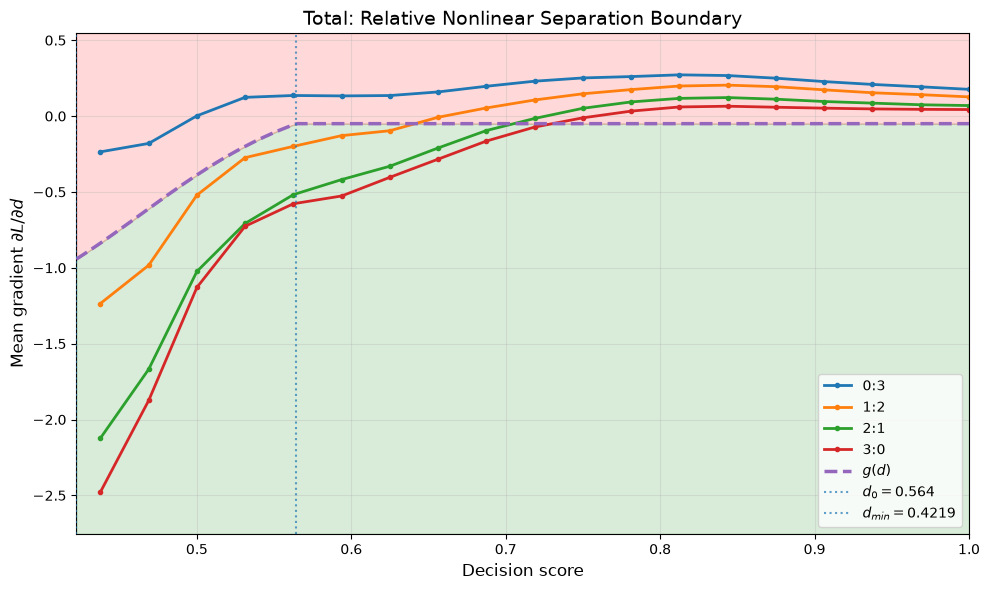

In [10]:
# ============================================================
# Plot final piecewise nonlinear boundary
# ============================================================

d_plot = torch.linspace(
    D_MIN,
    1.0,
    300,
)

with torch.no_grad():
    lambda_plot = (
        final_boundary(d_plot)
    ).cpu().numpy()

d_plot_np = d_plot.numpy()


plt.figure(figsize=(10, 6))


# ------------------------------------------------------------
# Determine y-axis range
# ------------------------------------------------------------

y_min = fit_df["mean_gradient"].min()
y_max = fit_df["mean_gradient"].max()

y_range = y_max - y_min

# Handle the case where all gradients are identical
if y_range == 0:
    y_range = 1.0

y_min -= 0.10 * y_range
y_max += 0.10 * y_range


# ------------------------------------------------------------
# Background regions
# ------------------------------------------------------------

# Below boundary → green
plt.fill_between(
    d_plot_np,
    y_min,
    lambda_plot,
    color="green",
    alpha=0.15,
    zorder=0,
)

# Above boundary → red
plt.fill_between(
    d_plot_np,
    lambda_plot,
    y_max,
    color="red",
    alpha=0.15,
    zorder=0,
)


# ------------------------------------------------------------
# Same color order as previous plots
# ------------------------------------------------------------

for ratio in ["0:3", "1:2", "2:1", "3:0"]:

    ratio_df = (
        fit_df[
            fit_df["retrieval_ratio"] == ratio
        ]
        .sort_values("decision_score")
    )

    if ratio_df.empty:
        continue

    plt.plot(
        ratio_df["decision_score"],
        ratio_df["mean_gradient"],
        marker="o",
        markersize=3,
        linewidth=2,
        label=ratio,
        zorder=2,
    )


# ------------------------------------------------------------
# Final piecewise nonlinear boundary
# ------------------------------------------------------------

plt.plot(
    d_plot_np,
    lambda_plot,
    linestyle="--",
    linewidth=2.5,
    label=r"$g(d)$",
    zorder=3,
)


# ------------------------------------------------------------
# Zero-crossing point
# ------------------------------------------------------------

plt.axvline(
    d_zero,
    linestyle=":",
    linewidth=1.5,
    alpha=0.7,
    label=fr"$d_0={d_zero:.3f}$",
    zorder=4,
)


# ------------------------------------------------------------
# Starting point of fitting region
# ------------------------------------------------------------

plt.axvline(
    D_MIN,
    linestyle=":",
    linewidth=1.5,
    alpha=0.7,
    label=f"$d_{{min}}={D_MIN}$",
    zorder=4,
)


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

plt.xlabel(
    "Decision score",
    fontsize=12,
)

plt.ylabel(
    r"Mean gradient $\partial L / \partial d$",
    fontsize=12,
)

plt.title(
    "Total: Relative Nonlinear Separation Boundary",
    fontsize=14,
)


# ------------------------------------------------------------
# Axis limits
# ------------------------------------------------------------

plt.xlim(
    D_MIN,
    1.0,
)

plt.ylim(
    y_min,
    y_max,
)


# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

plt.grid(
    True,
    alpha=0.3,
    zorder=1,
)


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

plt.legend()


plt.tight_layout()


# ------------------------------------------------------------
# Save + show
# ------------------------------------------------------------

OUTPUT_PATH = Path(
    "gradient_results/plots/"
    "gradient_vs_decision_score_total_nonlinear_boundary.png"
)

OUTPUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

plt.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight",
)

print(f"Saved: {OUTPUT_PATH}")

plt.show()

In [ ]:
RETRIEVAL_COST_L = -1.494137
RETRIEVAL_COST_U = 0.199348
RETRIEVAL_COST_K = 17.432991
RETRIEVAL_COST_C = 0.463704
RETRIEVAL_COST_D0 = 0.564456


def compute_retrieval_cost(
        total_decision_score: torch.Tensor,
    ) -> torch.Tensor:

        d = total_decision_score

        # ====================================================
        # Antiderivative G(d)
        # ====================================================

        numerator = (
            1.0
            + torch.exp(
                RETRIEVAL_COST_K
                * (d - RETRIEVAL_COST_C)
            )
        )

        denominator = (
            1.0
            + torch.exp(
                torch.tensor(
                    RETRIEVAL_COST_K
                    * (
                        RETRIEVAL_COST_D0
                        - RETRIEVAL_COST_C
                    ),
                    device=d.device,
                    dtype=d.dtype,
                )
            )
        )

        G_d = (
            RETRIEVAL_COST_L
            * (
                d
                - RETRIEVAL_COST_D0
            )
            + (
                (
                    RETRIEVAL_COST_U
                    - RETRIEVAL_COST_L
                )
                / RETRIEVAL_COST_K
            )
            * torch.log(
                numerator / denominator
            )
        )

        # ====================================================
        # Piecewise retrieval cost
        #
        # d < D0  -> -G(d)
        # d >= D0 -> 0.05 * d
        # ====================================================

        retrieval_cost = torch.where(
            d < RETRIEVAL_COST_D0,
            -G_d,
            0.05 * d,
        )

        return retrieval_cost.sum()


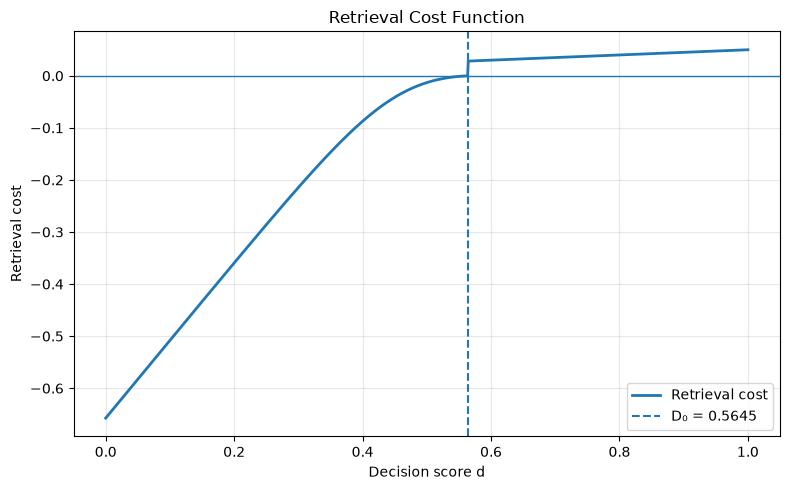

In [12]:
# ============================================================
# Plot Retrieval Cost Function
# ============================================================

import torch
import matplotlib.pyplot as plt

d_plot = torch.linspace(
    0.0,
    1.0,
    1000,
)

with torch.no_grad():
    cost_plot = torch.stack([
        compute_retrieval_cost(d.unsqueeze(0))
        for d in d_plot
    ])

plt.figure(figsize=(8, 5))

plt.plot(
    d_plot.numpy(),
    cost_plot.numpy(),
    linewidth=2,
    label="Retrieval cost",
)

plt.axvline(
    RETRIEVAL_COST_D0,
    linestyle="--",
    linewidth=1.5,
    label=f"D₀ = {RETRIEVAL_COST_D0:.4f}",
)

plt.axhline(
    0.0,
    linewidth=1,
)

plt.xlabel("Decision score d")
plt.ylabel("Retrieval cost")
plt.title("Retrieval Cost Function")

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()